# Decode the Bioreactor — 04 Mechanistic model + XGBoost
Combines the mechanistic model (notebook 02) with Philip's XGBoost (branch `philip/analysis`):
the mechanistic prediction at each sample time becomes an **input feature** of XGBoost, next to Philip's features (day-0 values, volume, cumulative / interval / next feeds).

Variants compared on the same 5 CV folds, scored with the challenge metric (mean of the 4 MAPEs):

| name | features | target |
|---|---|---|
| `null_per_day` | – | median per day |
| `mech` | – | mechanistic model alone |
| `xgb` | Philip's | log(y / y0) — Philip's model (+ seed averaging) |
| `mech+xgb_lfc` | Philip's + mech | log(y / y0) |
| `mech+xgb_resid` | Philip's + mech | log(y / mech) — XGBoost corrects the mechanistic model |

**No leakage**: in each fold the mechanistic parameters are fitted on the training batches only, and the mech features of *both* training and validation rows come from those parameters. Note: on training rows the mech prediction is in-sample (a bit better than on new batches), so XGBoost may trust it slightly too much — CV shows the honest effect.

Code: `src/bioreactor/xgb_features.py` (Philip's features, ported), `src/bioreactor/mech_xgb.py` (model, metric, template filling).

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bioreactor.data import load, to_arrays, STATES
from bioreactor.model import NAMES
from bioreactor.fit import fit_staged, initial_from_data
from bioreactor.xgb_features import build_features, feature_columns
from bioreactor.mech_xgb import MechXGB, add_mech_features, challenge_score, per_day_median, fill_template

df, tmpl, train_ids, test_ids = load(ROOT / "data")
splits = pd.read_csv(ROOT / "outputs" / "splits.csv")
dev_ids = splits.query("role == 'dev'").batch_id.tolist()
hold_ids = splits.query("role == 'holdout'").batch_id.tolist()
fold_of = splits.query("role == 'dev'").set_index("batch_id").fold.to_dict()

# mechanistic fit settings (same as notebooks 02/03) + cache of fitted parameters
MAX_NFEV_STAGE, MAX_NFEV, N_STARTS = 20, 60, 1
FIT_KW = dict(residual="log", loss="soft_l1", f_scale=0.1)
CACHE = ROOT / "outputs" / "params_cache"; CACHE.mkdir(parents=True, exist_ok=True)
USE_CACHE = True
SEEDS = (0, 1, 2)          # XGBoost seeds averaged per model
USE_FUTURE_FEEDS = True    # Philip's next_* features (feeds right after each sample)

F_all = build_features(df, use_future_feeds=USE_FUTURE_FEEDS)
print(F_all.shape, "feature rows;", len(feature_columns(F_all)), "base features")
F_all.head()

(793, 42) feature rows; 35 base features


,batch_id,elapsed_time,k,t,dt,log_volume,vol_ratio,dvol,log0_vcd,log0_tcd,...,cum_feed_d_per_vol,int_feed_d,n_feed_d,tsince_first_feed_d,next_feed_d,y_vcd,y_tcd,y_substrate,y_byproduct,to_predict
0,Batch1,0.996528,1,0.996528,0.996528,2.350831,0.999384,-0.006465,-0.020519,-0.014859,...,0.0,0.0,0,NaN,0.000000,1.909271,1.929805,3.830345,0.940785,False
1,Batch1,1.984722,2,1.984722,0.988194,2.354895,1.003455,0.042742,-0.020519,-0.014859,...,0.0,0.0,0,NaN,0.000000,4.574543,4.611517,2.827742,1.860896,False
2,Batch1,2.967361,3,2.967361,0.982639,2.369860,1.018584,0.158870,-0.020519,-0.014859,...,0.0,0.0,0,NaN,0.000000,7.489739,7.545903,2.362482,1.941632,False
3,Batch1,3.970833,4,3.970833,1.003472,2.393026,1.042456,0.250669,-0.020519,-0.014859,...,0.0,0.0,0,NaN,0.000000,14.300371,14.405872,2.263021,2.301048,False
4,Batch1,4.963889,5,4.963889,0.993056,2.435152,1.087309,0.470989,-0.020519,-0.014859,...,0.0,0.0,0,NaN,0.017048,19.394708,19.602812,2.569217,1.959836,False


In [2]:
def mech_params(ids, tag):
    """Mechanistic parameters fitted on `ids` (staged fit), or loaded from the cache."""
    f = CACHE / f"{tag}.csv"
    if USE_CACHE and f.exists():
        s = pd.read_csv(f, index_col=0).iloc[:, 0]
        if list(s.index) == NAMES:
            print(f"[{tag}] mechanistic parameters from cache"); return s.values
    t0 = time.time()
    p, _ = fit_staged(to_arrays(df, ids), None, p_init=initial_from_data(df, ids),
                      max_nfev_stage=MAX_NFEV_STAGE, max_nfev_final=MAX_NFEV,
                      n_starts=N_STARTS, verbose=False, **FIT_KW)
    pd.Series(p, index=NAMES).to_csv(f); print(f"[{tag}] mechanistic fit {time.time()-t0:.0f} s")
    return p

VARIANTS = {
    "xgb":            dict(target="lfc", use_mech=False),
    "mech+xgb_lfc":   dict(target="lfc", use_mech=True),
    "mech+xgb_resid": dict(target="mech_resid", use_mech=True),
}

def run_split(tr_ids, va_ids, tag):
    """Fit all variants on tr_ids, predict va_ids. Returns (scores table, predictions, models, F_va)."""
    p = mech_params(tr_ids, tag)
    F_tr = add_mech_features(F_all, df, p, tr_ids)
    F_va = add_mech_features(F_all, df, p, va_ids)
    Y_va = F_va[[f"y_{s}" for s in STATES]].set_axis(STATES, axis=1)
    preds = {"null_per_day": per_day_median(F_tr, F_va),
             "mech": F_va[[f"mech_{s}" for s in STATES]].set_axis(STATES, axis=1)}
    models = {}
    for name, kw in VARIANTS.items():
        models[name] = MechXGB(seeds=SEEDS, **kw).fit(F_tr)
        preds[name] = models[name].predict(F_va)
    scores = pd.DataFrame({n: challenge_score(Y_va, P) for n, P in preds.items()}).T
    return scores, preds, models, F_va

## 1. One fold (quick look)
First run fits the mechanistic model for this fold, unless it is in `outputs/params_cache/` already.

In [3]:
FOLD = 0
tr_ids = [b for b in dev_ids if fold_of[b] != FOLD]; va_ids = [b for b in dev_ids if fold_of[b] == FOLD]
t0 = time.time()
scores, preds, models, F_va = run_split(tr_ids, va_ids, tag=f"fold{FOLD}")
print(f"{time.time()-t0:.0f} s")
scores.round(2).sort_values("score")

[fold0] mechanistic parameters from cache
5 s


,vcd,tcd,substrate,byproduct,score
mech+xgb_lfc,6.51,6.53,8.63,12.31,8.49
xgb,6.76,6.63,9.66,11.08,8.53
mech+xgb_resid,7.04,7.11,8.27,13.26,8.92
null_per_day,8.16,8.11,9.97,11.93,9.54
mech,10.36,11.10,13.51,16.99,12.99


Which inputs does XGBoost use? (mean importance over seeds; top 15 per state for `mech+xgb_resid`)

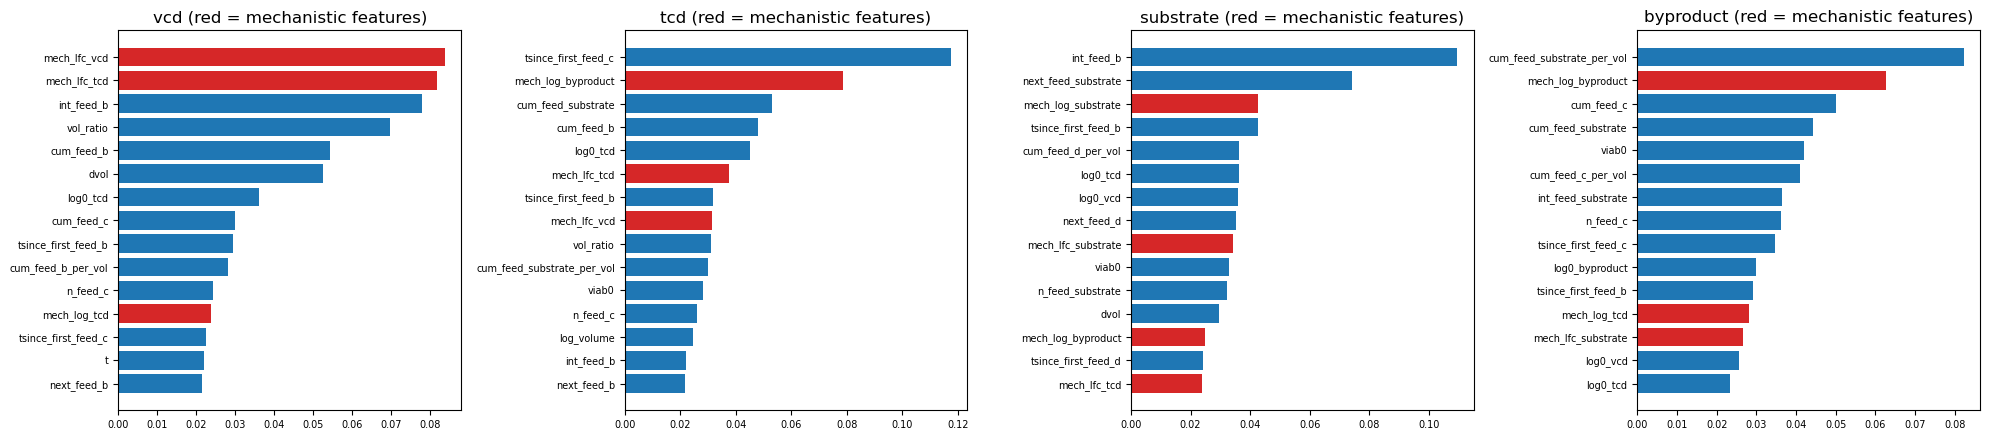

In [4]:
imp = models["mech+xgb_resid"].importances()
if imp.empty:
    print("Feature importance is unavailable for the fitted estimator. To use XGBoost importance, restart the kernel and refit with xgboost available.")
else:
    fig, ax = plt.subplots(1, len(imp.columns), figsize=(5 * len(imp.columns), 4.5), squeeze=False)
    for a, s in zip(ax[0], imp.columns):
        top = imp[s].sort_values().tail(15)
        a.barh(top.index, top.values, color=["tab:red" if c.startswith("mech_") else "tab:blue" for c in top.index])
        a.set_title(f"{s} (red = mechanistic features)")
        a.tick_params(labelsize=7)
    plt.tight_layout()
    plt.show()

Error by day for each variant (validation fold).

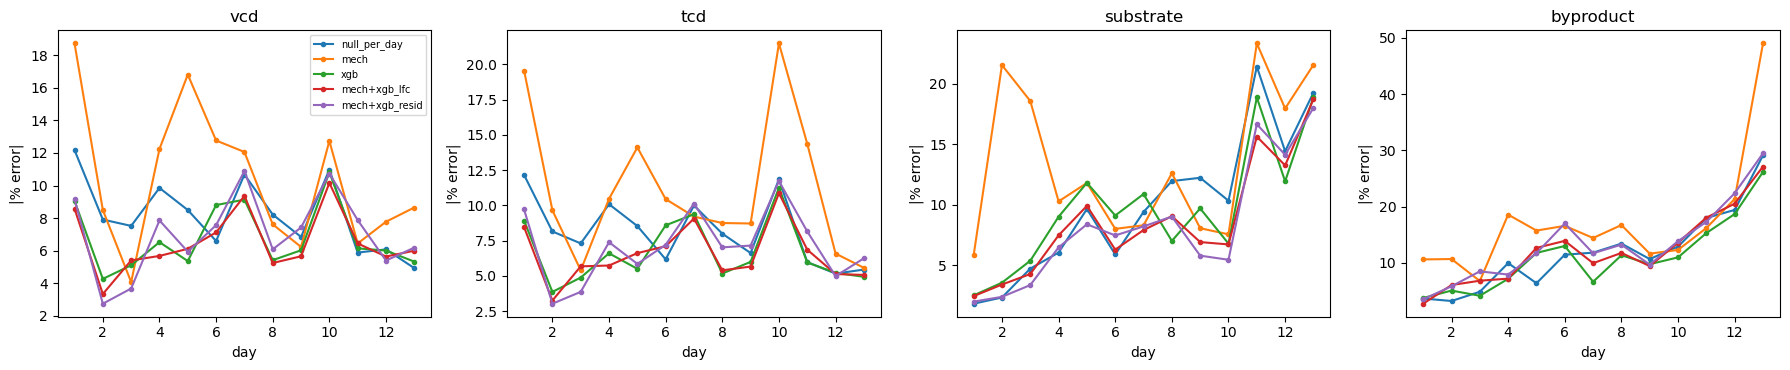

In [5]:
Y_va = F_va[[f"y_{s}" for s in STATES]].set_axis(STATES, axis=1)
day = np.rint(F_va.t).astype(int)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for name, P in preds.items():
    e = (100 * (P - Y_va).abs() / Y_va).groupby(day.to_numpy()).mean()
    for a, s in zip(ax, STATES):
        a.plot(e.index, e[s], "o-", ms=3, label=name)
for a, s in zip(ax, STATES):
    a.set_title(s); a.set_xlabel("day"); a.set_ylabel("|% error|")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 2. 5-fold cross-validation
Mechanistic parameters are cached per fold (`fold0` … `fold4`), so only the first run is slow.

In [10]:
RUN_CV = True
if RUN_CV:
    tabs = []
    for f in range(5):
        tr_ = [b for b in dev_ids if fold_of[b] != f]; va_ = [b for b in dev_ids if fold_of[b] == f]
        sc, *_ = run_split(tr_, va_, tag=f"fold{f}")
        tabs.append(sc.assign(fold=f)); print(f"fold {f}:", sc["score"].round(2).to_dict())
    cv = pd.concat(tabs).rename_axis("variant").reset_index()
    cv.to_csv(ROOT / "outputs" / "cv_scores_mech_xgb.csv", index=False)
    display(cv.groupby("variant")[STATES + ["score"]].agg(["mean", "std"]).round(2).sort_values(("score", "mean")))

[fold0] mechanistic parameters from cache
fold 0: {'null_per_day': 9.54, 'mech': 12.99, 'xgb': 8.53, 'mech+xgb_lfc': 8.49, 'mech+xgb_resid': 8.92}
[fold1] mechanistic parameters from cache
fold 1: {'null_per_day': 10.38, 'mech': 13.13, 'xgb': 10.08, 'mech+xgb_lfc': 9.92, 'mech+xgb_resid': 9.54}
[fold2] mechanistic parameters from cache
fold 2: {'null_per_day': 10.07, 'mech': 13.78, 'xgb': 10.32, 'mech+xgb_lfc': 10.28, 'mech+xgb_resid': 10.55}
[fold3] mechanistic parameters from cache
fold 3: {'null_per_day': 12.0, 'mech': 14.27, 'xgb': 11.39, 'mech+xgb_lfc': 11.3, 'mech+xgb_resid': 11.47}
[fold4] mechanistic parameters from cache
fold 4: {'null_per_day': 10.44, 'mech': 13.67, 'xgb': 10.2, 'mech+xgb_lfc': 9.85, 'mech+xgb_resid': 9.98}


vcd          tcd       substrate       byproduct        \
                 mean   std   mean   std      mean   std      mean   std   
variant                                                                    
mech+xgb_lfc     7.67  0.87   7.51  0.91     10.68  1.42     14.02  1.94   
mech+xgb_resid   7.52  0.41   7.42  0.41     10.74  1.60     14.68  2.03   
xgb              7.76  0.75   7.56  0.80     11.29  1.15     13.80  2.53   
null_per_day     8.58  0.55   8.65  0.59     11.69  1.40     13.04  2.79   
mech            10.77  0.50  11.62  0.72     15.09  1.68     16.79  2.66   

                score        
                 mean   std  
variant                      
mech+xgb_lfc     9.97  1.01  
mech+xgb_resid  10.09  0.97  
xgb             10.10  1.02  
null_per_day    10.49  0.92  
mech            13.57  0.52

## 3. Hold-out check — once, after choosing the variant from CV
Fit on all 39 dev batches, score the 10 hold-out batches.

In [9]:
RUN_HOLDOUT = True
if RUN_HOLDOUT:
    sc_h, *_ = run_split(dev_ids, hold_ids, tag="dev_all")
    display(sc_h.round(2).sort_values("score"))

[dev_all] mechanistic parameters from cache


,vcd,tcd,substrate,byproduct,score
mech+xgb_lfc,6.56,6.46,7.99,9.35,7.59
mech+xgb_resid,6.64,6.68,7.84,10.41,7.89
xgb,6.82,6.92,8.98,8.96,7.92
null_per_day,8.94,8.99,10.37,8.54,9.21
mech,10.76,10.93,12.50,12.32,11.63


## 4. Final: fit on all 49 batches → submission
Writes `outputs/submission_<variant>.csv` in the template format.

In [8]:
RUN_FINAL = False
VARIANT = "mech+xgb_resid"     # choose from the CV result
if RUN_FINAL:
    p_all = mech_params(train_ids, tag="all49")
    F_tr = add_mech_features(F_all, df, p_all, train_ids)
    F_te = add_mech_features(F_all, df, p_all, test_ids)
    model = MechXGB(seeds=SEEDS, **VARIANTS[VARIANT]).fit(F_tr)
    P_te = model.predict(F_te)
    sub = fill_template(tmpl, F_te, P_te)
    out = ROOT / "outputs" / f"submission_{VARIANT.replace('+', '_')}.csv"
    sub.to_csv(out, index=False); print("written", out)
    display(sub.head())